In [ ]:
from pathlib import Path
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, precision_recall_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import re
from email import message_from_string
from email.policy import default
from sklearn.base import BaseEstimator, TransformerMixin


In [ ]:
ham_dir = Path("data/spamassassin/easy_ham")
spam_dir = Path("data/spamassassin/spam")


In [35]:
hams = [file.read_text(errors="replace") for file in ham_dir.iterdir() if file.is_file()]
spams = [file.read_text(errors="replace") for file in spam_dir.iterdir() if file.is_file()]

In [36]:
emails = hams + spams
labels = [0] * len(hams) + [1] * len(spams)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    emails,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

In [38]:
vectorizer_pipeline = Pipeline([
    ("vectorizer", CountVectorizer())
])

In [42]:
X_train_vec = vectorizer_pipeline.fit_transform(X_train)

X_test_vec = vectorizer_pipeline.transform(X_test)

In [43]:
vectorizer = vectorizer_pipeline.named_steps["vectorizer"]

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Training shape:", X_train_vec.shape)
print("Testing shape:", X_test_vec.shape)

Vocabulary size: 84774
Training shape: (2401, 84774)
Testing shape: (601, 84774)


In [45]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[2000., 401.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.18,-1.79]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 84774)","[[2960., 236.,2064.,..., 0., 0., 0.], [ 549., 493., 148.,..., 2., 1., 3.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 84774)","[[ -5.94, -8.47, -6.3 ,...,-13.93,-13.93,-13.93], [ -6.67, -6.77, -7.97,...,-11.88,-12.28,-11.59]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,84774


In [48]:
pred = model.predict(X_test_vec)

In [55]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       501
           1       0.99      0.85      0.91       100

    accuracy                           0.97       601
   macro avg       0.98      0.92      0.95       601
weighted avg       0.97      0.97      0.97       601



[[500   1]
 [ 15  85]]


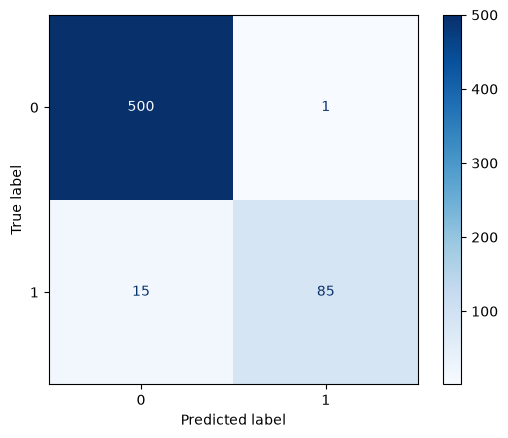

In [58]:
cm = confusion_matrix(y_test, pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, pred,cmap="Blues")

In [60]:
pred_prob = model.predict_proba(X_test_vec)

In [65]:
pred_prob[:,1:]

array([[1.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [4.57924808e-248],
       [9.20649817e-218],
       [0.00000000e+000],
       [1.21753790e-234],
       [0.00000000e+000],
       [9.18064461e-072],
       [0.00000000e+000],
       [1.00000000e+000],
       [9.98582811e-001],
       [0.00000000e+000],
       [1.00000000e+000],
       [2.31849592e-115],
       [1.18026945e-303],
       [4.26582007e-298],
       [2.22761118e-075],
       [0.00000000e+000],
       [1.00000000e+000],
       [5.93450009e-115],
       [8.45192829e-098],
       [0.00000000e+000],
       [1.00000000e+000],
       [0.00000000e+000],
       [2.32597666e-209],
       [1.16581004e-138],
       [0.00000000e+000],
       [1.10043347e-087],
       [5.09987856e-110],
       [2.40551615e-314],
       [1.74188717e-245],
       [8.63525106e-074],
       [1.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [0.00000000e+000],
       [1.01

In [66]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [67]:
vectorizer_pipeline = Pipeline([
    ("vectorizer", CountVectorizer())
])

X_train_new_vec = vectorizer_pipeline.fit_transform(X_train_new)
X_val_vec = vectorizer_pipeline.transform(X_val)

In [68]:
model = MultinomialNB()
model.fit(X_train_new_vec, y_train_new)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[1599., 321.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.18,-1.79]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 69818)","[[2386., 189.,1614.,..., 0., 0., 0.], [ 385., 404., 115.,..., 2., 1., 3.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 69818)","[[ -5.93, -8.46, -6.32,...,-13.7 ,-13.7 ,-13.7 ], [ -6.79, -6.74, -7.99,...,-11.65,-12.05,-11.36]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,69818


In [70]:
y_val_scores = model.predict_proba(X_val_vec)[:, 1]
y_val_scores

array([6.95365101e-109, 1.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 1.77050444e-079, 1.81234291e-202, 8.84478053e-078,
       1.89700654e-086, 1.00000000e+000, 3.57159284e-143, 1.10066560e-298,
       1.00000000e+000, 7.02458616e-217, 0.00000000e+000, 4.81934297e-287,
       1.61894763e-290, 6.51377497e-074, 0.00000000e+000, 3.65490039e-265,
       0.00000000e+000, 3.10517206e-077, 9.99999997e-001, 0.00000000e+000,
       2.67166758e-259, 7.27893716e-299, 0.00000000e+000, 1.00000000e+000,
       1.13362922e-284, 1.00193414e-085, 7.27984996e-262, 0.00000000e+000,
       0.00000000e+000, 7.78490363e-187, 0.00000000e+000, 1.57954026e-092,
       1.00000000e+000, 6.11852203e-077, 5.91295262e-075, 0.00000000e+000,
       3.99313505e-090, 1.23089520e-248, 4.45010412e-292, 2.63028565e-203,
       0.00000000e+000, 1.21063114e-096, 8.97410371e-067, 5.17139007e-290,
       1.86488299e-083, 0.00000000e+000, 3.55951733e-186, 0.00000000e+000,
       1.00000000e+000, 1

In [72]:
precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    y_val_scores
)

In [76]:
results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precisions[:-1],
    "recall": recalls[:-1]
})

results.head()

,threshold,precision,recall
0,0.000000e+00,0.166320,1.0
1,9.130333e-321,0.219780,1.0
2,1.377702e-319,0.220386,1.0
3,1.782638e-319,0.220994,1.0
4,1.819545e-319,0.221607,1.0


In [77]:
print("Scores:")
print(y_val_scores[:10])

print("\nThresholds:")
print(thresholds[:10])

print("\nPrecision:")
print(precisions[:10])

print("\nRecall:")
print(recalls[:10])


Scores:
[6.95365101e-109 1.00000000e+000 0.00000000e+000 0.00000000e+000
 0.00000000e+000 1.77050444e-079 1.81234291e-202 8.84478053e-078
 1.89700654e-086 1.00000000e+000]

Thresholds:
[0.00000000e+000 9.13033314e-321 1.37770205e-319 1.78263826e-319
 1.81954496e-319 1.10616357e-318 1.43975176e-318 1.65478889e-317
 6.08804280e-316 6.65992314e-316]

Precision:
[0.16632017 0.21978022 0.22038567 0.22099448 0.22160665 0.22222222
 0.22284123 0.22346369 0.22408964 0.2247191 ]

Recall:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [78]:
print("Minimum:", y_val_scores.min())
print("Maximum:", y_val_scores.max())

print("\nQuantiles:")
print(
    pd.Series(y_val_scores).quantile(
        [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
    )
)

Minimum: 0.0
Maximum: 1.0

Quantiles:
0.00     0.000000e+00
0.10     0.000000e+00
0.25    1.819545e-319
0.50    1.561352e-183
0.75     2.569279e-74
0.90     1.000000e+00
1.00     1.000000e+00
dtype: float64


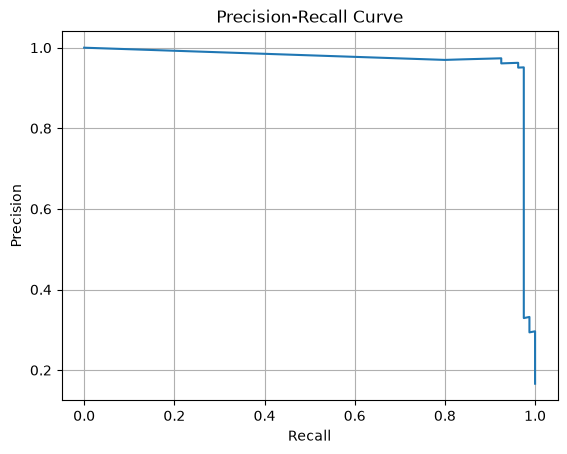

In [79]:
import matplotlib.pyplot as plt

plt.plot(recalls, precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()
plt.show()

In [80]:
import numpy as np

valid_indices = np.where(precisions[:-1] >= 0.95)[0]

best_idx = valid_indices[
    np.argmax(recalls[:-1][valid_indices])
]

best_threshold = thresholds[best_idx]

print("Threshold:", best_threshold)
print("Precision:", precisions[best_idx])
print("Recall:", recalls[best_idx])

Threshold: 3.848885959336827e-47
Precision: 0.9512195121951219
Recall: 0.975


In [81]:
y_val_pred = (y_val_scores >= best_threshold).astype(int)

In [82]:
print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       401
           1       0.95      0.97      0.96        80

    accuracy                           0.99       481
   macro avg       0.97      0.98      0.98       481
weighted avg       0.99      0.99      0.99       481



In [83]:
# تبدیل ایمیل‌های Test با همان Vectorizer آموزش‌دیده
X_test_vec = vectorizer_pipeline.transform(X_test)

# محاسبه احتمال Spam بودن
y_test_scores = model.predict_proba(X_test_vec)[:, 1]

# استفاده از Threshold انتخاب‌شده در Validation
y_test_pred = (y_test_scores >= best_threshold).astype(int)

In [84]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       501
           1       0.96      0.98      0.97       100

    accuracy                           0.99       601
   macro avg       0.98      0.99      0.98       601
weighted avg       0.99      0.99      0.99       601



In [85]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_test_pred))

[[497   4]
 [  2  98]]


In [116]:
from nltk.stem import PorterStemmer

class EmailPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        strip_headers=True,
        lowercase=True,
        remove_punctuation=True,
        replace_urls=True,
        replace_numbers=True,
        use_stemming=False
    ):
        self.strip_headers = strip_headers
        self.lowercase = lowercase
        self.remove_punctuation = remove_punctuation
        self.replace_urls = replace_urls
        self.replace_numbers = replace_numbers
        self.use_stemming = use_stemming

    def stem_words(self, text):
        stemmer = PorterStemmer()
        words = text.split()
        return " ".join(stemmer.stem(word) for word in words)

    def get_part_content(self, part):
        try:
            return part.get_content()
        except (LookupError, UnicodeError):
            payload = part.get_payload(decode=True)

            if payload is None:
                return ""

            charset = part.get_content_charset() or "utf-8"

            try:
                return payload.decode(charset, errors="replace")
            except LookupError:
                return payload.decode("utf-8", errors="replace")

    def get_body(self, email_text):
        msg = message_from_string(
            email_text,
            policy=default
        )

        if self.strip_headers:
            if msg.is_multipart():
                part = msg.get_body(preferencelist=("plain",))
                return self.get_part_content(part) if part else ""

            return self.get_part_content(msg)

        return email_text

    # متدهای get_body و fit قبلی را نگه دار

    def transform(self, X):
        cleaned_emails = []

        for email_text in X:
            text = self.get_body(email_text)

            if self.lowercase:
                text = text.lower()

            if self.replace_urls:
                text = re.sub(
                    r"https?://\S+|www\.\S+",
                    " URL ",
                    text
                )

            if self.replace_numbers:
                text = re.sub(r"\d+", " NUMBER ", text)

            if self.remove_punctuation:
                text = re.sub(r"[^\w\s]", " ", text)

            if self.use_stemming:
                text = self.stem_words(text)

            cleaned_emails.append(text)

        return cleaned_emails

    def fit(self, X, y=None):
        return self

In [134]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(use_stemming=True)),
    ("vectorizer", CountVectorizer())
])

X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

In [129]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SGD Classifier": SGDClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_new_vec, y_train_new)

    y_pred = model.predict(X_val_vec)

    print(f"\n{name}")
    print(classification_report(y_val, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       401
           1       0.97      0.93      0.95        80

    accuracy                           0.98       481
   macro avg       0.98      0.96      0.97       481
weighted avg       0.98      0.98      0.98       481


SGD Classifier
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       401
           1       0.84      0.82      0.83        80

    accuracy                           0.94       481
   macro avg       0.90      0.90      0.90       481
weighted avg       0.94      0.94      0.94       481



In [135]:
print(X_train_new_vec.shape)

(1920, 29350)


In [130]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(use_stemming=False)),
    ("vectorizer", CountVectorizer())
])

In [131]:
X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

In [132]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SGD Classifier": SGDClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_new_vec, y_train_new)

    y_pred = model.predict(X_val_vec)

    print(f"\n{name}")
    print(classification_report(y_val, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       401
           1       0.97      0.93      0.95        80

    accuracy                           0.98       481
   macro avg       0.98      0.96      0.97       481
weighted avg       0.98      0.98      0.98       481


SGD Classifier
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       401
           1       0.86      0.82      0.84        80

    accuracy                           0.95       481
   macro avg       0.91      0.90      0.90       481
weighted avg       0.95      0.95      0.95       481



In [133]:
print(X_train_new_vec.shape)

(1920, 36267)


In [136]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(
        strip_headers=False,
        use_stemming=False
    )),
    ("vectorizer", CountVectorizer())
])

X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SGD Classifier": SGDClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_new_vec, y_train_new)

    y_pred = model.predict(X_val_vec)

    print(f"\n{name}")
    print(classification_report(y_val, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       401
           1       0.96      0.94      0.95        80

    accuracy                           0.98       481
   macro avg       0.97      0.97      0.97       481
weighted avg       0.98      0.98      0.98       481


SGD Classifier
              precision    recall  f1-score   support

           0       0.99      0.96      0.98       401
           1       0.83      0.96      0.89        80

    accuracy                           0.96       481
   macro avg       0.91      0.96      0.93       481
weighted avg       0.96      0.96      0.96       481



In [139]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(
        strip_headers=False,
        use_stemming=False
    )),
    ("vectorizer", CountVectorizer(
        ngram_range=(1, 2)
    ))
])

X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_new_vec, y_train_new)

y_pred = model.predict(X_val_vec)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       401
           1       0.96      0.95      0.96        80

    accuracy                           0.99       481
   macro avg       0.98      0.97      0.97       481
weighted avg       0.99      0.99      0.99       481



In [140]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(
        strip_headers=False,
        use_stemming=False
    )),
    ("vectorizer", CountVectorizer(
        ngram_range=(1, 2),
        min_df=2
    ))
])

X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_new_vec, y_train_new)

y_pred = model.predict(X_val_vec)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       401
           1       0.96      0.95      0.96        80

    accuracy                           0.99       481
   macro avg       0.98      0.97      0.97       481
weighted avg       0.99      0.99      0.99       481



In [141]:
full_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(
        strip_headers=False,
        use_stemming=False
    )),
    ("vectorizer", CountVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.9
    ))
])

X_train_new_vec = full_pipeline.fit_transform(X_train_new)
X_val_vec = full_pipeline.transform(X_val)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_new_vec, y_train_new)

y_pred = model.predict(X_val_vec)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       401
           1       0.96      0.96      0.96        80

    accuracy                           0.99       481
   macro avg       0.98      0.98      0.98       481
weighted avg       0.99      0.99      0.99       481



In [142]:
final_pipeline = Pipeline([
    ("preprocessor", EmailPreprocessor(
        strip_headers=False,
        use_stemming=False
    )),
    ("vectorizer", CountVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.9
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])


In [143]:
final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('vectorizer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,strip_headers,False
,lowercase,True
,remove_punctuation,True
,replace_urls,True
,replace_numbers,True


In [144]:
y_test_pred = final_pipeline.predict(X_test)

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       501
           1       1.00      0.99      0.99       100

    accuracy                           1.00       601
   macro avg       1.00      0.99      1.00       601
weighted avg       1.00      1.00      1.00       601

